In [68]:
import pandas as pd

In [69]:
# Upload the csv file
from google.colab import files

files.upload()

Saving prabowo_mbg_kopdes.csv to prabowo_mbg_kopdes.csv


{'prabowo_mbg_kopdes.csv': b'"conversation_id_str","created_at","favorite_count","full_text","id_str","image_url","in_reply_to_screen_name","lang","location","quote_count","reply_count","retweet_count","tweet_url","user_id_str","username"\r\n"2105520867447115996","2026-10-01T05:47:40.000Z","4","@Sukirman2019 @aqfiazfan Goblog, lebih memuakkan Rezim Prabowo skrg kalii. Jauh bgt, kondisi skrg itu udh bener2 ga ketolong, mulai dr Koruptor, MBG, Kopdes, Kelakuan Parcok, Parjo, Pejabatnya jg.","2105535097919488506","","Sukirman2019","in","","0","2","0","https://x.com/sahabathabib/status/2105535097919488506","2994496326","sahabathabib"\r\n"2105530736942239989","2026-10-01T05:30:21.000Z","1","Semakin clear kalau Prabowo Presiden dan akan super power\n\nMBG dan Kopdes tetap akan lanjut dan semakin ah sudahlah \n\nMiliterisasi ranah sipil akan semakin masif dan \n\nSudah pasti 2029 akan mencalonkan lagi dan bukan dengan Gibran","2105530736942239989","","","in","","1","1","1","https://x.com/R_Pe

In [70]:
data = pd.read_csv('prabowo_mbg_kopdes.csv')

In [71]:
import re

def cleansing(sent):
  string = sent.lower()
  string = re.sub(r'http\S+', '', string)
  string = re.sub(r'@\w+', '', string)
  string = re.sub(r'#\w+', '', string)
  string = re.sub(r'\d+', '', string)
  string = re.sub(r'[^\w\s]', '', string)
  return string

In [72]:
data['full_text'] = data.full_text.apply(cleansing)
data.head()

,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username
0,2105520867447115996,2026-10-01T05:47:40.000Z,4,goblog lebih memuakkan rezim prabowo skrg ka...,2105535097919488506,NaN,Sukirman2019,in,NaN,0,2,0,https://x.com/sahabathabib/status/210553509791...,2994496326,sahabathabib
1,2105530736942239989,2026-10-01T05:30:21.000Z,1,semakin clear kalau prabowo presiden dan akan ...,2105530736942239989,NaN,NaN,in,NaN,1,1,1,https://x.com/R_Perkasa/status/210553073694223...,365900433,R_Perkasa
2,2105317288186708131,2026-10-01T03:44:27.000Z,0,antek antek prabowo lagi nyari duit itu kakk ...,2105504088364568671,NaN,ridetosolarr,in,NaN,0,1,0,https://x.com/aikacamayii/status/2105504088364...,1862307648525541378,aikacamayii
3,2105452703476551906,2026-10-01T00:20:16.000Z,0,miris gimana pendidikan mau maju dana pendidik...,2105452703476551906,https://pbs.twimg.com/media/HTgSEpLa8AA5LxZ.jpg,NaN,in,NaN,0,0,0,https://x.com/adajuga100/status/21054527034765...,772371244406583297,adajuga100
4,2105245837047771261,2026-10-01T00:04:11.000Z,0,presiden lagi sibuk urus mbg dan kopdes saba...,2105448657478938820,NaN,kompascom,in,NaN,0,0,0,https://x.com/AriD3AngeL/status/21054486574789...,68327748,AriD3AngeL


In [73]:
data.to_csv('sample_data/prabowo_mbg_kopdes_clean.csv', index=False)

In [74]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
import numpy as np
import pandas as pd
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords as stopwords_scratch

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [75]:
list_stopwords = stopwords_scratch.words('indonesian')
list_stopwords_en = stopwords_scratch.words('english')
list_stopwords.extend(list_stopwords_en)
list_stopwords.extend(['ya', 'yg', 'ga', 'yuk', 'dah', 'ngga', 'engga', 'ygy'])
stopwords = list_stopwords

In [76]:
data = data.full_text.to_list()
data[:10]

['  goblog lebih memuakkan rezim prabowo skrg kalii jauh bgt kondisi skrg itu udh bener ga ketolong mulai dr koruptor mbg kopdes kelakuan parcok parjo pejabatnya jg',
 'semakin clear kalau prabowo presiden dan akan super power\n\nmbg dan kopdes tetap akan lanjut dan semakin ah sudahlah \n\nmiliterisasi ranah sipil akan semakin masif dan \n\nsudah pasti  akan mencalonkan lagi dan bukan dengan gibran',
 ' antek antek prabowo lagi nyari duit itu kakk maklum dana buat mbg kopdes dan korupsinya kurang',
 'miris gimana pendidikan mau maju dana pendidikan tahun  diambil mbg rp triliun kemendikdasmen hanya dikasih rp triliun \n\n\n\n     ',
 ' presiden  lagi sibuk urus mbg dan kopdes sabar ya guys',
 ' mbg dan kopdes adalah penyakit  yg dibuat prabowo',
 'vietnam sibuk membuat teknologi baru dan manufaktur agar menjadi negara eksportir dan modern\n\nprabowo   masih aja sibuk mikirin bagi uang korupsi dari proyek mbg dan kopdes',
 'indonesia di tangan lo  kok makin ancur ya\n program andalan mb

In [77]:
vectorizer = TfidfVectorizer(stop_words=stopwords)
x = vectorizer.fit_transform(data[:100])

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['baiknya', 'berkali', 'kali', 'kurangnya', 'mata', 'olah', 'sekurang', 'setidak', 'tama', 'tidaknya'] not in stop_words.
  warnings.warn(


In [78]:
true_k = 8
model = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1)
model.fit(x)

KMeans(max_iter=100, n_init=1)

In [79]:
order_centroids = model.cluster_centers_.argsort()[:, ::-1]
terms = vectorizer.get_feature_names_out()

for i in range(true_k):
  print("Cluster %d:" % i),
  for ind in order_centroids[i, :10]:
    print(' %s' % terms[ind])
  print()

Cluster 0:
 antek
 gontor
 mampusss
 makan
 butuh
 gk
 uang
 fuck
 dana
 bakar

Cluster 1:
 presiden
 dll
 pendidikan
 mbg
 wok
 sekolah
 kopdes
 guys
 sabar
 triliun

Cluster 2:
 prabowo
 program
 kopdes
 mbg
 bilang
 sosialis
 tutup
 amp
 jokowi
 aja

Cluster 3:
 tp
 kebijakan
 bermasalah
 nyerang
 kuat
 blunder
 peduli
 pribadi
 serang
 gibranlah

Cluster 4:
 prabowo
 korupsi
 kopdes
 mbg
 menang
 pilih
 tni
 polri
 apbn
 pemerintahan

Cluster 5:
 anggaran
 fuck
 subsidi
 pemerintah
 nyata
 rakyat
 krisis
 lihat
 solusi
 pki

Cluster 6:
 gratis
 stop
 sekolah
 bikin
 kuliah
 kopdes
 kek
 kawal
 mbg
 ganti

Cluster 7:
 gak
 amp
 hasilnya
 indonesia
 mbg
 pertemuan
 lembaga
 lapas
 diadakan
 kopdes



In [80]:
from sklearn.metrics import silhouette_score

silhouette_score(x, labels=model.predict(x))

np.float64(0.0031186257948074593)

In [81]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=0)
reduced_features = pca.fit_transform(x.toarray())

reduced_cluster_centers = pca.transform(model.cluster_centers_)

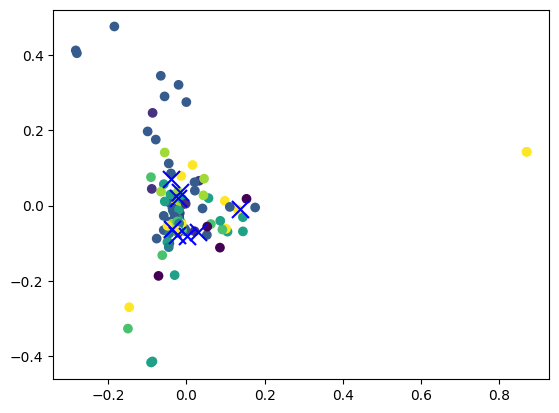

In [82]:
plt.scatter(reduced_features[:,0], reduced_features[:,1], c=model.predict(x))
plt.scatter(reduced_cluster_centers[:, 0], reduced_cluster_centers[:,1], marker='x',
            s=150, c='b')

In [83]:
import pickle

feature_bow = pickle.load(open("model/feature-bow.p", 'rb'))
model_nb = pickle.load(open("model/model-nb.p", 'rb'))
model_nn = pickle.load(open("model/model-nn.p", 'rb'))

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator CountVectorizer from version 0.22.2.post1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator MultinomialNB from version 0.22.2.post1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LabelBinarizer from version 0.22.2.post1 when using version 1.6.1. This might lead

In [84]:
import pandas as pd

data = pd.read_csv("sample_data/prabowo_mbg_kopdes_clean.csv")

In [85]:
def predict_sentiment(sent):
  text_feature = feature_bow.transform([sent])
  return model_nb.predict(text_feature)[0]

In [86]:
data['sentiment'] = data.full_text.apply(predict_sentiment)
data

,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username,sentiment
0,2105520867447115996,2026-10-01T05:47:40.000Z,4,goblog lebih memuakkan rezim prabowo skrg ka...,2105535097919488506,NaN,Sukirman2019,in,NaN,0,2,0,https://x.com/sahabathabib/status/210553509791...,2994496326,sahabathabib,negative
1,2105530736942239989,2026-10-01T05:30:21.000Z,1,semakin clear kalau prabowo presiden dan akan ...,2105530736942239989,NaN,NaN,in,NaN,1,1,1,https://x.com/R_Perkasa/status/210553073694223...,365900433,R_Perkasa,positive
2,2105317288186708131,2026-10-01T03:44:27.000Z,0,antek antek prabowo lagi nyari duit itu kakk ...,2105504088364568671,NaN,ridetosolarr,in,NaN,0,1,0,https://x.com/aikacamayii/status/2105504088364...,1862307648525541378,aikacamayii,neutral
3,2105452703476551906,2026-10-01T00:20:16.000Z,0,miris gimana pendidikan mau maju dana pendidik...,2105452703476551906,https://pbs.twimg.com/media/HTgSEpLa8AA5LxZ.jpg,NaN,in,NaN,0,0,0,https://x.com/adajuga100/status/21054527034765...,772371244406583297,adajuga100,neutral
4,2105245837047771261,2026-10-01T00:04:11.000Z,0,presiden lagi sibuk urus mbg dan kopdes saba...,2105448657478938820,NaN,kompascom,in,NaN,0,0,0,https://x.com/AriD3AngeL/status/21054486574789...,68327748,AriD3AngeL,negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,1965224067109392603,2025-09-09T01:21:44.000Z,3,pemerintahan macron kolaps\noposisi perancis b...,1965224067109392603,https://pbs.twimg.com/media/G0Xg26zbgAQ7mmP.jpg,NaN,in,NaN,0,0,0,https://x.com/ade206/status/1965224067109392603,303182883,ade206,negative
996,1965051513967136991,2025-09-08T13:56:04.000Z,1,mensos sampaikan tiga mandat prioritas preside...,1965051513967136991,https://pbs.twimg.com/media/G0VDqeTb0AA8yQ8.jpg,NaN,in,NaN,0,0,0,https://x.com/RadioElshinta/status/19650515139...,121640063,RadioElshinta,neutral
997,1963802799608844373,2025-09-05T03:14:07.000Z,3,bukan rahasia umum di banyak podcast rocky ge...,1963802799608844373,NaN,NaN,in,NaN,0,0,0,https://x.com/Marko_Omang/status/1963802799608...,438814409,Marko_Omang,neutral
998,1963128466389491943,2025-09-04T11:46:03.000Z,21,mungkin sekarang lu belum merasakan manfaatn...,1963569243607257467,NaN,Starryglowup,in,NaN,2,12,3,https://x.com/bosanpsbb/status/196356924360725...,1258100485791211522,bosanpsbb,negative


In [87]:
data.to_csv('sample_data/prabowo_mbg_kopdes_predicted.csv', index=False)

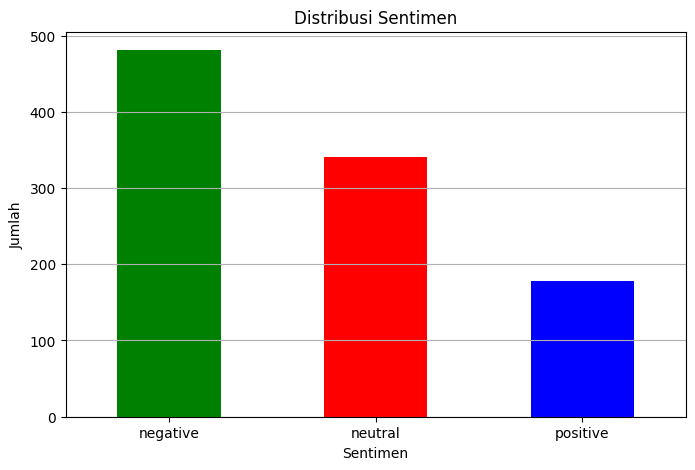

sentiment
negative    481
neutral     341
positive    178
Name: count, dtype: int64


In [88]:
import matplotlib.pyplot as plt

sentiment_counts = data['sentiment'].value_counts()

plt.figure(figsize=(8, 5))
sentiment_counts.plot(kind='bar', color=['green', 'red', 'blue'])
plt.title('Distribusi Sentimen')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

print(sentiment_counts)

In [89]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter

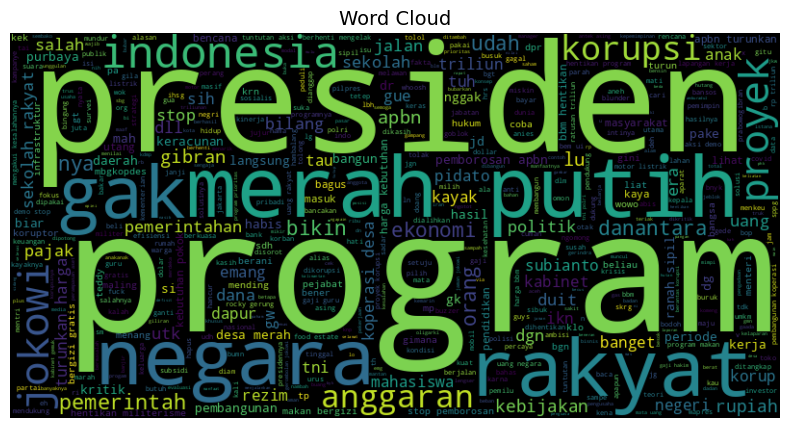

In [100]:
wc_clean = WordCloud(stopwords=stopwords, background_color='black', max_words=500, width=800, height=400).generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wc_clean, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud', fontsize=14)
plt.show()

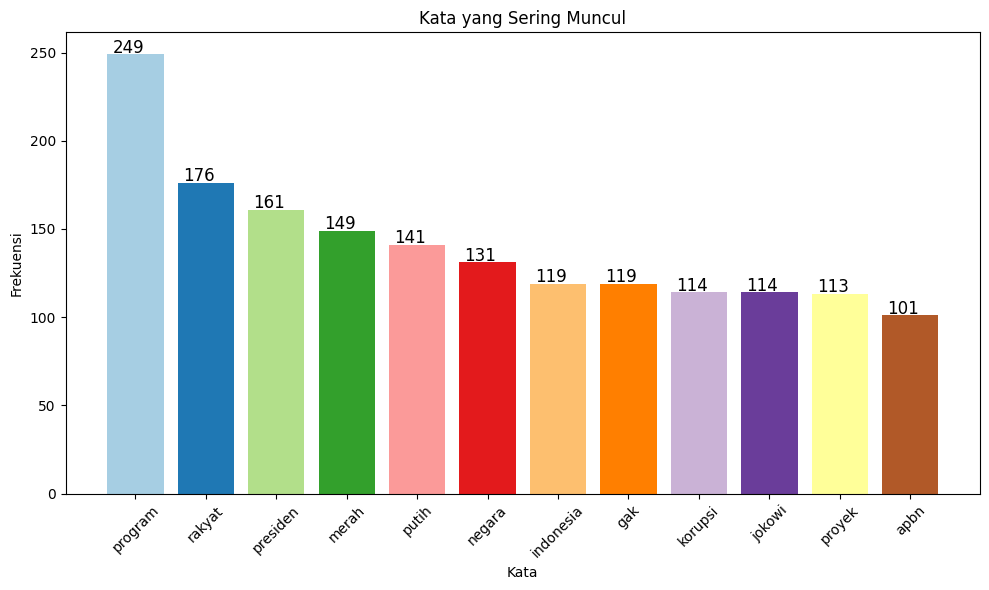

In [99]:
additional_stopwords = ['prabowo', 'mbg', 'kopdes', 'dan', 'di', 'yg', 'yang', 'itu', 'ini', 'ada', 'amp', 'untuk', 'dengan', 'dari', 'akan', 'bisa', 'kalo', 'ga', 'ya', 'aja']
stopwords.extend(additional_stopwords)

stopwords = list(set(stopwords))

text = ' '.join(data['full_text'].astype(str).tolist())
words = text.split()

filtered_words = [word for word in words if word not in stopwords and len(word) > 1]

word_counts = Counter(filtered_words)
top_words = word_counts.most_common(12)
words_clean, counts_clean = zip(*top_words)

colors_clean = plt.cm.Paired(range(len(words_clean)))
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(words_clean, counts_clean, color=colors_clean)

ax.set_xlabel('Kata')
ax.set_ylabel('Frekuensi')
ax.set_title('Kata yang Sering Muncul')
ax.set_xticks(range(len(words_clean)))
ax.set_xticklabels(words_clean, rotation=45)

for bar, num in zip(bars, counts_clean):
    ax.text(bar.get_x() + bar.get_width() / 2 - 0.1, num + 1, str(num), fontsize=12, color='black', ha='center')

plt.tight_layout()
plt.show()


In [92]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline

In [93]:
df = pd.read_csv('sample_data/prabowo_mbg_kopdes_predicted.csv')
df.head()

,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username,sentiment
0,2105520867447115996,2026-10-01T05:47:40.000Z,4,goblog lebih memuakkan rezim prabowo skrg ka...,2105535097919488506,NaN,Sukirman2019,in,NaN,0,2,0,https://x.com/sahabathabib/status/210553509791...,2994496326,sahabathabib,negative
1,2105530736942239989,2026-10-01T05:30:21.000Z,1,semakin clear kalau prabowo presiden dan akan ...,2105530736942239989,NaN,NaN,in,NaN,1,1,1,https://x.com/R_Perkasa/status/210553073694223...,365900433,R_Perkasa,positive
2,2105317288186708131,2026-10-01T03:44:27.000Z,0,antek antek prabowo lagi nyari duit itu kakk ...,2105504088364568671,NaN,ridetosolarr,in,NaN,0,1,0,https://x.com/aikacamayii/status/2105504088364...,1862307648525541378,aikacamayii,neutral
3,2105452703476551906,2026-10-01T00:20:16.000Z,0,miris gimana pendidikan mau maju dana pendidik...,2105452703476551906,https://pbs.twimg.com/media/HTgSEpLa8AA5LxZ.jpg,NaN,in,NaN,0,0,0,https://x.com/adajuga100/status/21054527034765...,772371244406583297,adajuga100,neutral
4,2105245837047771261,2026-10-01T00:04:11.000Z,0,presiden lagi sibuk urus mbg dan kopdes saba...,2105448657478938820,NaN,kompascom,in,NaN,0,0,0,https://x.com/AriD3AngeL/status/21054486574789...,68327748,AriD3AngeL,negative


In [94]:
x = df['full_text']
y = df['sentiment']

In [95]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('model', LogisticRegression())
])

In [96]:
pipeline.fit(x_train, y_train)

Pipeline(steps=[('tfidf', TfidfVectorizer(max_features=5000)),
                ('model', LogisticRegression())])

In [97]:
y_pred = pipeline.predict(x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.61      0.93      0.74        92
     neutral       0.70      0.54      0.61        72
    positive       1.00      0.08      0.15        36

    accuracy                           0.64       200
   macro avg       0.77      0.52      0.50       200
weighted avg       0.71      0.64      0.59       200



In [98]:
joblib.dump(pipeline, 'model/model_lr.joblib')

['model/model_lr.joblib']